# 01 · Dados: o que há de fato no ICAERUS
Tudo aqui é calculado dos arquivos reais baixados (`data/raw/zenodo`). Objetivo: **validar antes de treinar** (tamanho dos objetos, lacunas de anotação, divisão por voo).

In [1]:
import sys, json, collections; sys.path.insert(0, '..')
import numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110})
from training.zenodo_plan import load, reliable_flights, split_of
imgs, flight, farm, lab, rows = load()
info = reliable_flights(flight, lab, rows)
print('imagens listadas no ZIP:', len(imgs), '| arquivos de rótulo baixados:', len(lab), '| caixas nos rótulos:', int(sum(len(v) for v in lab.values())))

imagens listadas no ZIP: 1385 | arquivos de rótulo baixados: 1079 | caixas nos rótulos: 2666


## 1 · O resumo oficial bate com os rótulos? (voos 'confiáveis')
Voo confiável = nº de caixas nos rótulos igual ao do resumo oficial (±1). Os demais **não** entram (rótulo ausente não significa ausência de gado).

In [2]:
import pandas as pd
df = pd.DataFrame([{'voo': k, 'fazenda': v['farm'], 'alt_m': v['alt'], 'drone': v['drone'], 'caixas_resumo': v['summary_boxes'], 'caixas_rotulos': v['label_boxes'], 'confiavel': v['reliable']} for k, v in info.items()])
print(df.to_string(index=False))
print('\nresumo oficial total:', int(df.caixas_resumo.sum()), '| nos rótulos:', int(df.caixas_rotulos.sum()), '| voos confiáveis:', int(df.confiavel.sum()), 'de', len(df))

                 voo    fazenda  alt_m   drone  caixas_resumo  caixas_rotulos  confiavel
DJI_202306051814_022     Mauron    100 DJI-M3T             91              91       True
DJI_202306051839_025     Mauron    100 DJI-M3T            408             408       True
DJI_202306071624_028     Mauron    100 DJI-M3T            357             357       True
DJI_202306071703_029     Mauron    100 DJI-M3T             23              23       True
DJI_202306071745_034     Mauron    100 DJI-M3T             46              46       True
DJI_202306071745_035     Mauron    100 DJI-M3T            122             122       True
DJI_202311071416_061     Mauron    100 DJI-M3E            142               0      False
DJI_202311071416_062     Mauron    100 DJI-M3E            124               0      False
DJI_202311071541_064     Mauron    100 DJI-M3E            170               0      False
DJI_202311071541_065     Mauron     60 DJI-M3E            290               0      False
DJI_202308091442_012 

## 2 · Tamanho dos objetos (por que fatiar)
Lado equivalente da caixa (√área) em pixels da imagem **original**, e como ficaria se a imagem inteira fosse reduzida a 640 px.

lado equivalente (px, original): mediana 45.8 | p10 31.6 | p90 73.1
após reduzir a imagem para 640 px: mediana 6.7 px


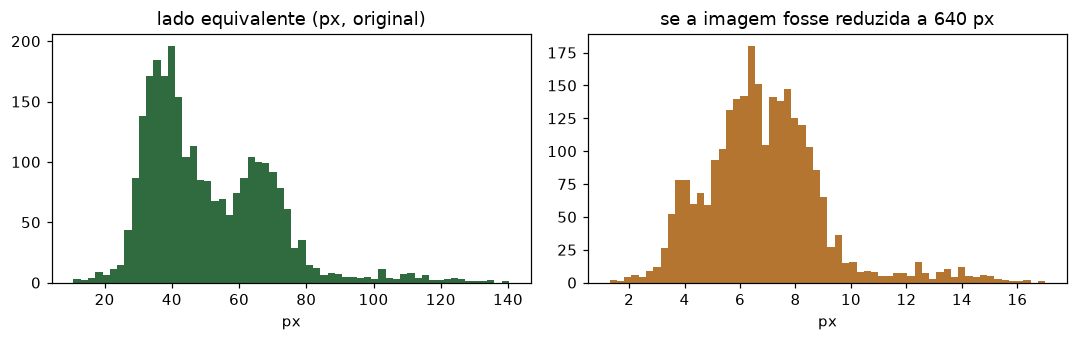

In [3]:
sz, fl = [], []
for s, v in lab.items():
    if s in imgs and len(v):
        wh = imgs[s]  # (nome, tamanho_zip)
        f = flight[s]; W = 4000 if '4000' in info.get(f, {}).get('size', '') else 5280; H = 3000 if W == 4000 else 3956
        sz += list(np.sqrt(v[:, 3] * W * v[:, 4] * H)); fl += [max(W, H)] * len(v)
sz, fl = np.array(sz), np.array(fl)
print('lado equivalente (px, original): mediana %.1f | p10 %.1f | p90 %.1f' % (np.median(sz), *np.percentile(sz, [10, 90])))
print('após reduzir a imagem para 640 px: mediana %.1f px' % np.median(sz * 640 / fl))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(sz, 60, color='#2f6b3f'); ax[0].set_title('lado equivalente (px, original)'); ax[0].set_xlabel('px')
ax[1].hist(sz * 640 / fl, 60, color='#b3752f'); ax[1].set_title('se a imagem fosse reduzida a 640 px'); ax[1].set_xlabel('px')
plt.tight_layout(); plt.show()

## 3 · Divisão por voo/fazenda (decidida antes de qualquer modelo)

In [4]:
plan = json.load(open('../data/raw/zenodo/download_plan.json'))['order']
d = pd.DataFrame(plan)
print(d.groupby(['split', 'farm', 'flight']).agg(imagens=('stem', 'count'), com_gado=('boxes', lambda x: int((x > 0).sum())), caixas=('boxes', 'sum')).to_string())
tiles = json.load(open('../data/yolo_tiles/manifest.json'))
print('\ntiles (total, com gado, caixas):', tiles['stats(tiles,tiles_com_gado,caixas)'])

                                    imagens  com_gado  caixas
split farm    flight                                         
test  Jalogny DJI_202306231103_031       17        13      77
              DJI_202306271323_032       23        19      94
              DJI_202309151045_056       19        15     214
              DJI_202309261339_058       18        14     209
              DJI_202309261339_059       15        11     215
train Derval  DJI_202308091442_012       29        25     115
      Mauron  DJI_202306051814_022        7         3      91
              DJI_202306051839_025       19        15     408
              DJI_202306071703_029        2         1      23
              DJI_202306071745_034        2         1      46
              DJI_202306071745_035        7         3     122
val   Mauron  DJI_202306071624_028       41        37     357

tiles (total, com gado, caixas): {'train': [346, 164, 1437], 'val': [820, 132, 617]}


**Leitura.** (1) As anotações do ICAERUS (v1 baixada) têm lacunas reais: por isso só voos consistentes foram usados. (2) O animal típico mede ~46 px numa foto de 4000 px; reduzida a 640 px ficaria com ~7 px: detectar exige **resolução nativa em fatias**. (3) O teste é uma **fazenda inédita** (Jalogny), então mede generalização, não memorização do voo.